# El LCR y el NSFR sobre los reportes de llamada del banco que quebró en 2023

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** los cuadernos 01 a 04 de este tema
- **Tiempo de lectura:** unos 45 minutos

## Objetivos

Al terminar este cuaderno puedes:

- calcular el stock de activos líquidos de alta calidad (HQLA) con los topes a los activos de Nivel 2, las salidas y entradas por categoría, el tope a las entradas y el coeficiente de cobertura de liquidez (LCR), con cada intermedio;
- decir por qué el LCR de este caso es "una fórmula de Basilea sobre agregados del reporte de llamada" y nunca la razón informada o regulatoria del banco;
- leer cómo un supuesto de mapeo de los clientes mueve la razón de 20% a 72%;
- ver qué necesita la razón de financiamiento estable neto (NSFR) que los agregados del reporte de llamada no traen, y leer el LCR frente al período de supervivencia del mismo banco.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==0.9.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 0.8.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Dos documentos versionados del caso C16 (agregados reales del reporte de llamada de la FDIC del banco que quebró el 2023-03-10 hasta el 2022-12-31, comportamiento y depósitos sintéticos, clase de licencia `mirror-allowed`):

- `data/derived/C16/lcr-standard.json`: la variante que aplica el LCR de Basilea al balance en 30 días corridos: el stock HQLA, las filas de salidas y entradas, las salidas netas, la razón y la sensibilidad al mapeo de clientes, además del balance.
- `data/derived/C16/list-adverse.json`: la escalera LiST Adverso del cuaderno 01, leída aquí para la comparación con el período de supervivencia.

Las tablas de tasas son el estándar LCR del Marco de Basilea (BCBS, LCR20 a LCR99, en vigor desde 2019-12-15) y su estándar NSFR (NSF20 a NSF99), guardadas por el motor como datos del módulo con su párrafo; el motor nunca reproduce el texto. El reporte de llamada no trae el tipo de cliente, así que cómo se mapea un depósito a una categoría LCR es una convención del producto, propuesta y declarada, nunca una clasificación regulatoria.

In [2]:
# Cargar el documento LCR versionado y el documento LiST Adverso (el cuaderno está tres carpetas bajo la raíz del repositorio)
ROOT = Path("../../..").resolve()
standard = json.loads((ROOT / "data" / "derived" / "C16" / "lcr-standard.json").read_text(encoding="utf-8"))
adverse = json.loads((ROOT / "data" / "derived" / "C16" / "list-adverse.json").read_text(encoding="utf-8"))
out = standard["outputs"]
lcr = out["lcr"]

for name, doc in (("lcr-standard", standard), ("list-adverse", adverse)):
    print(name, "| calculado con riskvalidation", doc["provenance"]["riskvalidation_version"], "| instalado", rv.__version__)
print("etiqueta:", lcr["label"], "| razón informada o regulatoria:", ("sí" if lcr["reported_or_regulatory"] else "no"))
print(lcr["statement"]["es"])

lcr-standard | calculado con riskvalidation 0.8.1 | instalado 0.8.1
list-adverse | calculado con riskvalidation 0.8.1 | instalado 0.8.1
etiqueta: basel-formula-on-call-report-aggregates | razón informada o regulatoria: no
Una fórmula LCR de Basilea aplicada a agregados del reporte de llamada FDIC con supuestos declarados y comportamiento sintético de depósitos: no es el LCR informado ni regulatorio del banco.


## Método

### Paso 1: el stock de HQLA y los topes

El stock es la suma de los activos de Nivel 1, Nivel 2A y Nivel 2B después de recortes, menos dos ajustes que hacen cumplir los topes (Nivel 2 como máximo 40% del stock, Nivel 2B como máximo 15%; Marco de Basilea LCR30.38 y LCR30.39, BCBS):

$$\mathrm{HQLA} = L_1 + L_{2A} + L_{2B} - \mathrm{Adj}_{15} - \mathrm{Adj}_{40}$$

$$\mathrm{Adj}_{15} = \max\!\Bigl(L_{2B} - \tfrac{15}{85}(L_1 + L_{2A}),\; L_{2B} - \tfrac{15}{60}L_1,\; 0\Bigr), \qquad \mathrm{Adj}_{40} = \max\!\Bigl(L_{2A} + L_{2B} - \mathrm{Adj}_{15} - \tfrac{2}{3}L_1,\; 0\Bigr)$$

El Nivel 1 no tiene límite. La celda siguiente toma los tres niveles del documento, calcula a mano los dos ajustes a partir de las ecuaciones (cada intermedio) y luego llama a `hqla_stock`.

In [3]:
# Los ajustes de HQLA a mano desde las ecuaciones, y luego el acervo del motor, contra el bloque versionado
from riskvalidation.regulatory.lcr_nsfr import hqla_stock

levels = lcr["hqla"]
l1, l2a, l2b = levels["l1"], levels["l2a"], levels["l2b"]
adj15 = max(l2b - 15 / 85 * (l1 + l2a), l2b - 15 / 60 * l1, 0.0)
adj40 = max(l2a + l2b - adj15 - 2 / 3 * l1, 0.0)
by_hand = l1 + l2a + l2b - adj15 - adj40
stock = hqla_stock(l1, l2a, l2b)

print("L1, L2A, L2B (miles de millones de USD:)", round(l1 / 1e6, 3), round(l2a / 1e6, 3), round(l2b / 1e6, 3))
print("Adj15 =", round(adj15 / 1e6, 3), "| Adj40 =", round(adj40 / 1e6, 3), "| HQLA a mano =", round(by_hand / 1e6, 3))
print("motor: HQLA, proporción del Nivel 2, proporción del Nivel 2B:", round(stock.hqla / 1e6, 3), round(stock.l2_share, 4), round(stock.l2b_share, 4))
print("igual que el documento:", ("sí" if np.isclose(stock.hqla, levels["hqla"]) and np.isclose(stock.adj_40, levels["adj_40"]) else "no"), "| topes:", levels["caps"])

L1, L2A, L2B (miles de millones de USD:) 18.909 31.204 0.0
Adj15 = 0.0 | Adj40 = 18.598 | HQLA a mano = 31.516
motor: HQLA, proporción del Nivel 2, proporción del Nivel 2B: 31.516 0.4 0.0
igual que el documento: sí | topes: {'l2_cap': 0.4, 'l2b_cap': 0.15}


El tope de Nivel 2 se activa exactamente: la proporción de Nivel 2 del stock es 0,40. El banco tiene más activos de Nivel 2A de los que el tope deja contar frente a sus activos de Nivel 1 (el Nivel 2 puede ser como máximo dos tercios del Nivel 1), así que una parte de ellos no entra en el stock.

### Paso 2: salidas y entradas por categoría

Cada categoría del LCR tiene una tasa: la salida de un saldo es $\text{saldo} \times \text{tasa}$, y el total es la suma sobre las categorías (LCR40 y LCR99). El motor guarda las tasas como `LCR_OUTFLOW_RATES` y `LCR_INFLOW_RATES`; `lcr_outflows` y `lcr_inflows` toman los saldos por categoría, rechazan una categoría fuera de la tabla (un `KeyError` que la nombra) y devuelven una fila por categoría. El mapeo de los depósitos del reporte de llamada a las categorías es el del documento (depósitos asegurados como minoristas menos estables, no asegurados como corporativos no financieros, oficinas extranjeras como otras personas jurídicas, un mapeo central declarado). La celda siguiente llama a ambas funciones con los saldos del documento.

In [4]:
# Las filas de salidas y entradas desde los saldos del documento
from riskvalidation.regulatory.lcr_nsfr import lcr_inflows, lcr_outflows

outflows = lcr_outflows({row["category"]: row["balance"] for row in lcr["outflows"]})
inflows = lcr_inflows({row["category"]: row["balance"] for row in lcr["inflows"]})

print(f"{'categoría':38s}{'saldo (mil millones USD)':>26s}{'tasa':>8s}{'monto (mil millones USD)':>26s}")
for side, result in (("salidas", outflows), ("entradas", inflows)):
    for row in result.rows:
        print(f"{row.key:38s}{row.balance / 1e6:26.3f}{row.rate:8.2f}{row.amount / 1e6:26.3f}   {side}")
    print(f"{'total':38s}{'':26s}{'':8s}{result.total / 1e6:26.3f}   {side}")
print("mismos totales que el documento:", ("sí" if np.isclose(outflows.total, lcr["total_outflows"]) and np.isclose(inflows.total, lcr["total_inflows"]) else "no"))

categoría                               saldo (mil millones USD)    tasa  monto (mil millones USD)
retail_less_stable                                         9.990    0.10                     0.999   salidas
non_financial_corporate                                  151.592    0.40                    60.637   salidas
other_legal_entity                                        13.899    1.00                    13.899   salidas
secured_other                                              1.757    1.00                     1.757   salidas
total                                                                                       77.292   salidas
secured_lending_other                                      0.707    1.00                     0.707   entradas
retail_and_nonfinancial_wholesale                         19.810    0.50                     9.905   entradas
total                                                                                       10.612   entradas
mismos totales que el docu

### Paso 3: salidas netas y la razón

Las entradas no pueden compensar más del 75% de las salidas, así que la salida neta nunca baja de un cuarto de las salidas (LCR40.1), y la razón es el stock sobre la salida neta (LCR20.4; se exige al menos 1 en tiempos normales, y una razón bajo 1 en tensión no es un incumplimiento):

$$\mathrm{net} = O - \min(I,\; 0.75\,O), \qquad \mathrm{LCR} = \frac{\mathrm{HQLA}}{\mathrm{net}}$$

`net_cash_outflows` devuelve las entradas contadas, la salida neta y si el tope se activa; `lcr_ratio` rechaza una salida neta menor o igual a cero (la razón no está definida, nunca es infinita). La celda siguiente corre ambas.

In [5]:
# Las salidas netas con el tope de 75 por ciento, y la razón, contra los valores versionados
from riskvalidation.regulatory.lcr_nsfr import lcr_ratio, net_cash_outflows

net = net_cash_outflows(outflows.total, inflows.total)
ratio = lcr_ratio(stock.hqla, net.net)

print("entradas contadas (miles de millones de USD):", round(net.inflows_counted / 1e6, 3), "| el tope se activa:", ("sí" if net.cap_binds else "no"))
print("salidas netas (miles de millones de USD):", round(net.net / 1e6, 3), "| versionadas:", round(lcr["net_outflows"] / 1e6, 3))
print("LCR =", round(ratio, 6), "| versionado:", round(lcr["ratio"], 6), "| igual:", ("sí" if np.isclose(ratio, lcr["ratio"]) else "no"))
print("una razón bajo 1 en tensión no es un incumplimiento: se espera que la institución vigile su caída (la nota del documento)")

entradas contadas (miles de millones de USD): 10.612 | el tope se activa: no
salidas netas (miles de millones de USD): 66.68 | versionadas: 66.68
LCR = 0.472641 | versionado: 0.472641 | igual: sí
una razón bajo 1 en tensión no es un incumplimiento: se espera que la institución vigile su caída (la nota del documento)


### Paso 4: la sensibilidad al mapeo de clientes

El saldo no asegurado es 151,6 mil millones de USD de 175,5 mil millones de depósitos, así que cómo se clasifica decide la razón. El documento corre tres mapeos de ese saldo: como corporativos no financieros (el central, 40% de salida), como depósitos operacionales (25%) y como otras personas jurídicas tales como instituciones financieras (100%). La celda siguiente vuelve a correr el motor con cada categoría y compara con la banda versionada.

In [6]:
# Recalcular la razón con el saldo no asegurado en cada una de las tres categorías de la banda de mapeo
uninsured = next(row["balance"] for row in lcr["outflows"] if row["category"] == "non_financial_corporate")
fixed = {row["category"]: row["balance"] for row in lcr["outflows"] if row["category"] != "non_financial_corporate"}
names = {"central": "central", "band-operational": "operacional", "band-other-legal-entity": "otras personas jurídicas"}

print(f"{'mapeo':28s}{'salidas (mil millones USD)':>30s}{'netas (mil millones USD)':>26s}{'LCR':>10s}{'versionado':>14s}")
band = []
for entry in lcr["mapping_sensitivity"]:
    balances = dict(fixed)
    balances[entry["lcr_category"]] = balances.get(entry["lcr_category"], 0.0) + uninsured
    total = lcr_outflows(balances).total
    netted = net_cash_outflows(total, inflows.total)
    value = lcr_ratio(stock.hqla, netted.net)
    band.append(value)
    print(f"{names[entry['mapping_id']]:28s}{total / 1e6:30.3f}{netted.net / 1e6:26.3f}{value:10.4f}{entry['ratio']:14.4f}")
print("misma banda que el documento:", ("sí" if np.allclose(band, [entry["ratio"] for entry in lcr["mapping_sensitivity"]]) else "no"))

mapeo                           salidas (mil millones USD)  netas (mil millones USD)       LCR    versionado
central                                             77.292                    66.680    0.4726        0.4726
operacional                                         54.553                    43.941    0.7172        0.7172
otras personas jurídicas                           168.247                   157.635    0.1999        0.1999
misma banda que el documento: sí


### Paso 5: lo que necesita el NSFR

La razón de financiamiento estable neto compara el financiamiento estable que tiene un banco con el que requieren sus activos (Marco de Basilea NSF20.2, BCBS):

$$\mathrm{NSFR} = \frac{\mathrm{ASF}}{\mathrm{RSF}} = \frac{\sum_i f_i^{\mathrm{ASF}}\, L_i}{\sum_j f_j^{\mathrm{RSF}}\, A_j}$$

donde los factores $f$ dependen del **vencimiento residual** de cada pasivo y activo (menos de 6 meses, 6 meses a 1 año, 1 año o más). El reporte de llamada da los saldos pero no esos vencimientos para los valores y los préstamos, y el documento no versiona ningún NSFR. Este paso es un ejercicio didáctico, no un resultado del producto: asigna cada saldo a un factor de las tablas del motor con una cota inferior y una superior donde el vencimiento se desconoce, y muestra qué pueden decir solos los agregados. El mapeo siguiente es un supuesto de este cuaderno, rotulado como tal.

In [7]:
# Un mapeo didáctico del balance a los factores del NSFR, con un factor inferior y uno superior donde se desconoce el vencimiento
from riskvalidation.regulatory.lcr_nsfr import nsfr_asf, nsfr_ratio, nsfr_rsf

items = {item["item_id"]: item["amount"] for item in out["balance_sheet"]["items"]}
securities = items["securities-htm"] + items["securities-afs"]
# partida: (monto, clave del factor inferior, clave del factor superior); una sola clave dos veces significa que el vencimiento no hace falta
liabilities = {
    "deposits-insured": (items["deposits-insured"], "less_stable_retail_deposits", "less_stable_retail_deposits"),
    "deposits-uninsured": (items["deposits-uninsured"], "funding_lt_1y_non_financial_corporates", "funding_lt_1y_non_financial_corporates"),
    "deposits-foreign": (items["deposits-foreign"], "other_liabilities", "other_funding_6m_to_1y"),
    "repo-borrowings": (items["repo-borrowings"], "other_liabilities", "other_liabilities"),
    "fhlb": (items["fhlb"], "other_liabilities", "long_term_liabilities_ge_1y"),
    "other-liabilities": (items["other-liabilities"], "other_liabilities", "other_liabilities"),
    "equity": (items["equity"], "regulatory_capital", "regulatory_capital"),
}
assets = {
    "cash": (items["cash"], "coins_banknotes_reserves", "coins_banknotes_reserves"),
    "reverse-repo": (items["reverse-repo"], "loans_fi_lt_6m_other", "loans_fi_lt_6m_other"),
    "securities": (securities, "unencumbered_level_1", "non_hqla_securities_ge_1y"),
    "loans": (items["loans"], "other_assets_lt_1y", "other_loans_ge_1y_rw_gt_35"),
    "other-assets": (items["other-assets"], "other_assets", "other_assets"),
}
# El ASF y el RSF del motor bajo el factor inferior y el superior de cada partida (las partidas que comparten factor se suman primero)
totals = {}
for name, table, engine in (("ASF", liabilities, nsfr_asf), ("RSF", assets, nsfr_rsf)):
    for position, bound in ((1, "lower"), (2, "upper")):
        grouped = {}
        for values in table.values():
            grouped[values[position]] = grouped.get(values[position], 0.0) + values[0]
        totals[(name, bound)] = engine(grouped)

print("saldos en miles de millones de USD (pasivos, activos):", round(sum(v[0] for v in liabilities.values()) / 1e6, 3), round(sum(v[0] for v in assets.values()) / 1e6, 3))
print("ASF (inferior, superior; miles de millones de USD):", round(totals[("ASF", "lower")] / 1e6, 3), round(totals[("ASF", "upper")] / 1e6, 3))
print("RSF (inferior, superior; miles de millones de USD):", round(totals[("RSF", "lower")] / 1e6, 3), round(totals[("RSF", "upper")] / 1e6, 3))
print("NSFR banda:", round(nsfr_ratio(totals[("ASF", "lower")], totals[("RSF", "upper")]), 4), "a", round(nsfr_ratio(totals[("ASF", "upper")], totals[("RSF", "lower")]), 4))

saldos en miles de millones de USD (pasivos, activos): 209.026 209.026
ASF (inferior, superior; miles de millones de USD): 100.243 122.192
RSF (inferior, superior; miles de millones de USD): 47.67 167.277
NSFR banda: 0.5993 a 2.5633


Una banda tan ancha dice una sola cosa: los agregados solos no identifican el NSFR. La razón podría estar bajo 1 o muy por encima según los vencimientos de 117 mil millones de valores y 74 mil millones de préstamos, que es la razón por la que un producto apoyado en agregados del reporte de llamada versiona el LCR (cuyas tasas dependen de los tipos de cliente y del horizonte de 30 días) y ningún NSFR.

### Paso 6: el LCR frente al período de supervivencia

El mismo banco se ve débil bajo el LCR y sobrevive unos dos meses bajo LiST Adverso. Las dos medidas difieren en lo que suponen sobre la **velocidad** de las salidas y sobre lo que cuenta como **líquido**. La celda siguiente las pone lado a lado: la proporción de la base de depósitos que sale en 30 días bajo cada una, y el stock HQLA frente al CBC. El informe de Basilea sobre la turbulencia de 2023 lista las tasas de salida de depósitos del LCR como 3% a 40% en 30 días (BCBS, 2023, Tabla A.1).

In [8]:
# La proporción de salida a 30 días de los depósitos bajo el LCR y bajo LiST Adverso, y el acervo de HQLA contra la CBC
from riskvalidation.liquidity.runoff import TABLE_A1_LCR_RANGE

lad = adverse["outputs"]["path"]["ladder"]
deposit_base = adverse["outputs"]["scoring"]["model_deposit_base"]
deposit_outflows = sum(sum(s["outflows"][:30]) for s in lad["segments"])
deposit_rows = ("retail_less_stable", "non_financial_corporate", "other_legal_entity")
lcr_deposit_outflows = sum(row["amount"] for row in lcr["outflows"] if row["category"] in deposit_rows)
low, high, days = TABLE_A1_LCR_RANGE
cumulative = np.cumsum(np.sum([s["outflows"] for s in lad["segments"]], axis=0)) / deposit_base
reach_day = int(np.argmax(cumulative >= lcr_deposit_outflows / deposit_base)) + 1

print("proporción de salida a 30 días de la base de depósitos, LCR:", round(lcr_deposit_outflows / deposit_base, 4))
print("proporción de salida a 30 días de la base de depósitos, LiST Adverso:", round(deposit_outflows / deposit_base, 4))
print("día en que LiST Adverso alcanza la proporción del LCR, y su proporción al día 125:", reach_day, round(float(cumulative[-1]), 4))
print("rango de las tasas de depósitos del LCR en la Tabla A.1 (mínima, máxima, días):", low, high, days)
print("stock HQLA y CBC (miles de millones de USD):", round(stock.hqla / 1e6, 3), round(adverse["outputs"]["cbc"]["total_liquidity_value"] / 1e6, 3))
print("LCR =", round(lcr["ratio"], 4), "| período de supervivencia bajo LiST Adverso (días):", adverse["outputs"]["path"]["survival"]["day"])

proporción de salida a 30 días de la base de depósitos, LCR: 0.4304
proporción de salida a 30 días de la base de depósitos, LiST Adverso: 0.247
día en que LiST Adverso alcanza la proporción del LCR, y su proporción al día 125: 72 0.6001
rango de las tasas de depósitos del LCR en la Tabla A.1 (mínima, máxima, días): 0.03 0.4 30
stock HQLA y CBC (miles de millones de USD): 31.516 71.673
LCR = 0.4726 | período de supervivencia bajo LiST Adverso (días): 62


La última celda dibuja las dos vistas. A la izquierda, el LCR bajo los tres mapeos frente al requisito de 1: el mapeo decide si el banco está en 20%, 47% o 72%. A la derecha, la proporción acumulada de salida de la base de depósitos bajo LiST Adverso en 125 días, con la proporción de salida a 30 días del LCR marcada: el LCR supone en 30 días una proporción de los depósitos que LiST Adverso alcanza solo mucho después.

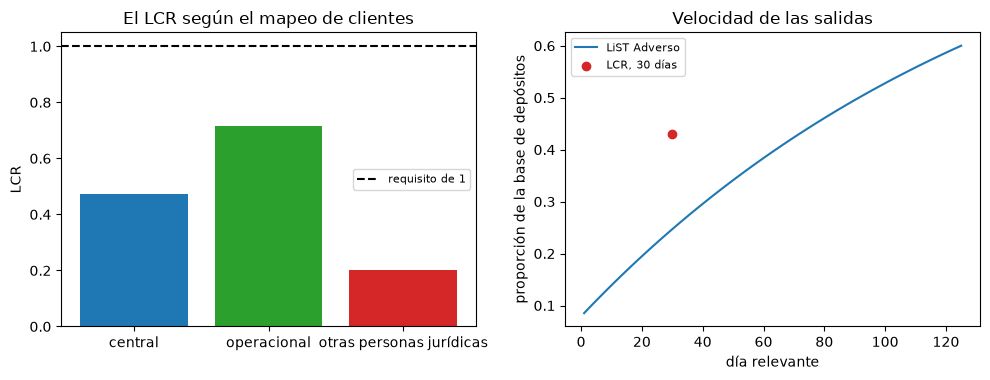

In [9]:
# Dibujar el LCR bajo los tres mapeos y la proporción de salida de depósitos de LiST Adverso contra la proporción del LCR
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.9))

labels = [names[entry["mapping_id"]] for entry in lcr["mapping_sensitivity"]]
left.bar(labels, band, color=["tab:blue", "tab:green", "tab:red"])
left.axhline(1.0, color="black", linestyle="--", label="requisito de 1")
left.set_ylabel("LCR")
left.set_title("El LCR según el mapeo de clientes")
left.legend(fontsize=8)

right.plot(np.arange(1, len(cumulative) + 1), cumulative, color="tab:blue", label="LiST Adverso")
right.scatter([30], [lcr_deposit_outflows / deposit_base], color="tab:red", zorder=3, label="LCR, 30 días")
right.set_xlabel("día relevante")
right.set_ylabel("proporción de la base de depósitos")
right.set_title("Velocidad de las salidas")
right.legend(fontsize=8)
fig.tight_layout()
plt.show()

## Resultados

- **HQLA.** Los niveles son 18,909 mil millones de USD de Nivel 1, 31,204 de Nivel 2A y nada de Nivel 2B. Los ajustes son 0 para el tope de 15% y 18,598 mil millones para el tope de 40%, así que el stock es 31,516 mil millones, a mano y con el motor, y el Nivel 2 es exactamente 0,4 de él. El documento coincide.
- **Salidas, entradas y la razón.** Las salidas son 77,292 mil millones (60,637 del saldo no asegurado al 40%, 13,899 de las oficinas extranjeras al 100%, 1,757 de financiación garantizada y 0,999 de los depósitos asegurados al 10%) y las entradas 10,612 mil millones, todas contadas porque el tope de 75% no se activa. La salida neta es 66,680 mil millones y el LCR es 31,516 / 66,680 = 0,472641, igual al documento.
- **El mapeo.** La razón es 0,4726 bajo el mapeo central, 0,7172 si el saldo no asegurado son depósitos operacionales y 0,1999 si son otras personas jurídicas: un factor de más de tres, con los tres valores reproducidos. Un único LCR para este banco escondería la banda.
- **El NSFR.** Con las cotas declaradas, el ASF está entre 100,243 y 122,192 mil millones y el RSF entre 47,670 y 167,277 mil millones, así que el NSFR queda entre 0,5993 y 2,5633. La banda es demasiado ancha para decir algo sobre cumplimiento, y esa es la lección: los agregados del reporte de llamada no identifican el NSFR. Es un cálculo didáctico con el mapeo de este cuaderno, no un resultado del producto.
- **LCR frente a supervivencia.** El LCR supone que 0,4304 de la base de depósitos sale en 30 días (sobre el rango de 3% a 40% de las tasas de depósitos del LCR porque el saldo de las oficinas extranjeras se mapea al 100%); LiST Adverso tiene 0,247 a los 30 días, alcanza 0,4304 solo el día 72 y 0,6001 el día 125. Por el lado de los activos el stock HQLA es 31,516 mil millones mientras el CBC es 71,673 mil millones. El LCR de 0,4726 y el período de supervivencia de 62 días son ambos correctos, para supuestos distintos de velocidad y de qué es líquido.

Lo que este cuaderno no muestra: el LCR como cifra regulatoria (la etiqueta del documento lo prohíbe), el LCR y el NSFR combinados de un declarante real, ni el efecto de otro horizonte. La razón es una propiedad del mapeo declarado y de un comportamiento sintético.

## Resumen

- El HQLA es Nivel 1 más Nivel 2A más Nivel 2B menos dos ajustes de tope; aquí el tope de 40% del Nivel 2 se activa exactamente.
- La salida neta es la salida menos las entradas hasta el 75% de ella, y la razón es el stock sobre ella; el motor rechaza una razón indefinida.
- El mapeo de clientes de un reporte de llamada es un supuesto, y mueve la razón por un factor de más de tres; un resultado debe mostrar la banda, no solo el valor central.
- El NSFR necesita vencimientos residuales que los agregados no traen.
- El LCR y el período de supervivencia responden preguntas distintas con supuestos distintos de velocidad y de qué es líquido; léelos juntos.

**Qué probar a continuación.** Mueve el saldo no asegurado a la categoría `operational_insured_portion` de la tabla del motor y mira qué hace la razón; luego sigue con el cuaderno 06.

## Referencias

- BCBS, Basel Framework, LCR standard (LCR20, LCR30, LCR40 and LCR99, in force 2019-12-15). https://www.bis.org/committees/bcbs/basel-framework/standard/lcr
- BCBS, Basel Framework, NSFR standard (NSF20, NSF30 and NSF99 Tables 1 to 3, in force 2019-12-15). https://www.bis.org/committees/bcbs/basel-framework/standard/nsf/99/inforce/2019-12-15/published/2019-12-15
- ECB Banking Supervision (2019), Sensitivity analysis of liquidity risk, stress test 2019, methodological note (2019-02-06). https://www.bankingsupervision.europa.eu/ecb/pub/pdf/ssm.ECB_sensitivity_analysis_of_liquidity_risk-stress_test_2019-methodological_note_20190206~6771e88926.en.pdf
- BCBS (2023), Report on the 2023 banking turmoil, Box A, Table A.1. https://www.bis.org/bcbs/publ/d555.htm